<a href="https://colab.research.google.com/github/markjschmidt/PET_List/blob/main/MJS_Claude_Agent_Randoms_IEC_20261112.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<a href="https://colab.research.google.com/github/markjschmidt/PET_List/blob/main/MJS_Claude_Agent_Randoms_IEC_20261112.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Claude agent: visualizing random coincidences in a NEMA/IEC phantom scan

**Prompt 1:** *This file contains LOR data for a NEMA/IEC Phantom with a very small dose (90 µCi) mixed in the body
section; no dose in the spheres; a 968 µCi dose in a syringe 1 cm in front of the phantom outside of the axial FOV,
and a 400 µCi source at the foot end of the phantom 1 cm beyond, outside of the axial FOV. This creates a large
number of Random Coincidence Events mixed with True Coincidence Events. In the screen capture I300_high_randoms,
the center 5 cm lung insert has reduced contrast due to the high number of false coincidence events. There ideally
would be 0 events in the center lung section. This has a maximum of 31 counts, several times higher than the baseline
image I300_low_randoms. The CT attenuation correction aggravates this problem by increasing the counts, Randoms in
this case, found at body center. In our Colab Agents Notebook, how would we visualize these Randoms falsely identified
as true coincidence events? They randomly fit within the PET coincidence timing window, so are accepted. There is a
good estimate of randoms by using the delays, but two events arriving within the 4.6 ns coincidence window (676 FOV)
will most likely be accepted.*

**Prompt 2:** *Yes, build the randoms notebook and open a PR.*

This notebook extends the starter agent (`MJS_Claude_Starter_Agent_PET_List_20261109.ipynb`) with tools that
visualize randoms. You can run every plot directly (section 5, no API cost) or ask Claude questions and let it choose
the tools (section 6).

## Background: why randoms can't be removed event by event

* A **random** is two 511 keV photons from *different* annihilations that happen to arrive within the coincidence
  window (±2.3 ns for the 676 FOV, i.e. TOF bins −119 to +119 × 19.53 ps). It passes the same energy and timing tests
  as a true coincidence, so **no single prompt can be labelled "random"**.
* The **delayed window** (DELAY events) pairs singles with a time offset, so it can only contain randoms. The delays
  give the randoms *distribution*: how many randoms to expect on each LOR, at each TOF position.
* So randoms are visualized **statistically**: plot prompts and delays the same way and compare. Where prompts ≈ delays,
  nearly every accepted event is random.
* Randoms rate on an LOR ≈ 2τ·S<sub>a</sub>·S<sub>b</sub> (window × singles rates of the two crystals). Activity
  **outside the axial FOV** adds singles but few trues, so it drives randoms up.
* Randoms have **no TOF information**: their time difference is uniform across the window, so along each LOR they
  spread evenly over the whole FOV, **including the lung insert**, where trues should be zero.
* **Attenuation correction** multiplies each LOR by exp(∫µ dl). LORs through the body center have the largest
  factors, so randoms on those LORs are amplified most, exactly at the lung insert.

## 1. Install and authenticate

Put your key in Colab **🔑 Secrets** as `ANTHROPIC_API_KEY` (with Notebook access on). Sections 4 and 5 work
without a key; only section 6 calls the Claude API.

In [1]:
!pip install -q -U anthropic matplotlib scipy
!pip install -q "pandas==2.2.3"

In [2]:
import os
import anthropic
from google.colab import userdata

os.environ["ANTHROPIC_API_KEY"] = userdata.get("ANTHROPIC_API_KEY")
client = anthropic.Anthropic()
MODEL = "claude-opus-5-5"
print("anthropic SDK version:", anthropic.__version__)

anthropic SDK version: 2.8.0


## 2. Get the data file

Upload `iec_randoms50k.txt` (in the repository) or another listPrint file. Files written by the Windows listPrint
utility are **UTF-16** encoded; the loader below detects this automatically.

In [3]:
from google.colab import files

uploaded = files.upload()                 # choose iec_randoms50k.txt
DATA_PATH = "/content/" + next(iter(uploaded))
print("Data file:", DATA_PATH)

# Alternative, if the repository is public: download straight from GitHub
# !wget -q https://raw.githubusercontent.com/markjschmidt/PET_List/main/iec_randoms50k.txt -O /content/iec_randoms50k.txt
# DATA_PATH = "/content/iec_randoms50k.txt"

Saving iec_randoms50k.txt to iec_randoms50k.txt
Data file: /content/iec_randoms50k.txt


## 3. Loader and geometry

On loading, every event gets four derived coordinates:

* **TOF position `(x, y)`**: the most likely annihilation point along the LOR. The offset from the LOR midpoint is
  `c·Δt/2` = 299.8 mm/ns × 19.53 ps / 2 = **2.93 mm per TOF bin**, toward `xa` when TOF is negative.
  This sign was checked on the repo's point-source files: `3OCLK_0_1000.txt` lands at (322, 19) mm (3 o'clock) and
  `src_at_bottom_24934.txt` at (−8, −242) mm (bottom); the opposite sign scatters them by ~350 mm.
* **Sinogram coordinates `(s, φ)`**: signed distance of the LOR from the scanner center, and LOR angle 0–180°.

Crystal positions use radius 382 mm (764 mm ring diameter, no depth of interaction), crystal 0 at 3 o'clock, IDs
clockwise. Images are drawn with y up, so crystal 144 (6 o'clock) is at the bottom.

**Limits of this view:** placing each event at one TOF point is not a reconstruction. The 320 ps timing resolution
blurs each point by about 48 mm FWHM along the LOR, about the size of the 5 cm lung insert, and there is no
attenuation, scatter or normalization correction.

In [4]:
import json
import re

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.ndimage import gaussian_filter

N_CRYSTALS = 576
HALF_RING = N_CRYSTALS // 2
RING_RADIUS_MM = 382.0                 # 764 mm ring diameter / 2
AXIAL_PITCH_MM = 4.1                   # 164 mm axial FOV / 40 crystals
TOF_PS_PER_BIN = 19.53                 # tofTstampScale
MM_PER_TOF_BIN = 299.8e-3 * TOF_PS_PER_BIN / 2   # c * dt / 2 = 2.93 mm

IMG_HALF_MM = 340.0                    # image field of view: +/- 340 mm
IMG_BINS = 85                          # 8 mm pixels

DATA = {}                              # shared state between tool calls

EVENT_RE = re.compile(
    r"(PROMPT|DELAY):\s*xa\((\d+)\) xb\((\d+)\) tof\(([-]?\d+)\) za\((\d+)\) zb\((\d+)\)"
)
TIME_RE = re.compile(r"Total time\s*=\s*([\d.]+)\s*seconds")


def read_listprint_text(path):
    """Read a listPrint file as text, detecting UTF-16 (Windows listPrint output) or UTF-8."""
    raw = open(path, "rb").read()
    if raw[:2] in (b"\xff\xfe", b"\xfe\xff"):
        enc = "utf-16"
    elif raw[:3] == b"\xef\xbb\xbf":
        enc = "utf-8-sig"
    elif raw[:400].count(b"\x00") > 100:      # UTF-16 without a byte-order mark
        enc = "utf-16-le"
    else:
        enc = "utf-8"
    return raw.decode(enc, errors="replace"), enc


def add_geometry(df):
    """Add TOF position (x, y) in mm and sinogram coordinates (s in mm, phi in degrees)."""
    ta = df["xa"].to_numpy() * 2 * np.pi / N_CRYSTALS
    tb = df["xb"].to_numpy() * 2 * np.pi / N_CRYSTALS
    # crystal coordinates: clockwise from 3 o'clock, drawn with y up
    ax_, ay_ = RING_RADIUS_MM * np.cos(ta), -RING_RADIUS_MM * np.sin(ta)
    bx_, by_ = RING_RADIUS_MM * np.cos(tb), -RING_RADIUS_MM * np.sin(tb)
    length = np.hypot(ax_ - bx_, ay_ - by_)
    length[length == 0] = 1.0
    ux, uy = (ax_ - bx_) / length, (ay_ - by_) / length       # unit vector from b toward a
    mx, my = (ax_ + bx_) / 2, (ay_ + by_) / 2                 # LOR midpoint

    offset = -df["tof"].to_numpy() * MM_PER_TOF_BIN          # negative TOF -> closer to xa
    df["x"] = mx + offset * ux
    df["y"] = my + offset * uy

    phi = np.arctan2(uy, ux) + np.pi / 2                      # direction of the LOR normal
    s = mx * np.cos(phi) + my * np.sin(phi)                   # signed distance from center
    high = phi >= np.pi                                       # fold angles into [0, pi)
    phi, s = np.where(high, phi - np.pi, phi), np.where(high, -s, s)
    low = phi < 0
    phi, s = np.where(low, phi + np.pi, phi), np.where(low, -s, s)
    df["s"] = s
    df["phi"] = np.degrees(phi)
    return df


def _split():
    """Return (prompts, delays) DataFrames, or (None, None) if no file is loaded."""
    df = DATA.get("df")
    if df is None:
        return None, None
    return df[df["type"] == "PROMPT"], df[df["type"] == "DELAY"]


def _image(g, sigma_px=1.0):
    """2D histogram of TOF positions, lightly smoothed. Indexed [x, y]."""
    h, _, _ = np.histogram2d(g["x"], g["y"], bins=IMG_BINS,
                             range=[[-IMG_HALF_MM, IMG_HALF_MM]] * 2)
    return gaussian_filter(h, sigma_px) if sigma_px else h


NOT_LOADED = "Error: no file loaded yet. Call load_listprint first."

## 4. The tools

Each tool is a plain Python function with `@beta_tool`; the docstring tells Claude when to use it. Plotting tools
draw the figure in the notebook **and** return the key numbers as JSON, because Claude reads the numbers, not the
picture.

In [5]:
from anthropic import beta_tool


@beta_tool
def load_listprint(path: str) -> str:
    """Load a Philips Vereos listPrint .txt file (UTF-8 or UTF-16) and return a summary with event counts,
    acquisition time, rates and the randoms fraction (delays / prompts). Must be called before any other tool.

    Args:
        path: Path to the listPrint .txt file, e.g. /content/iec_randoms50k.txt.
    """
    try:
        text, enc = read_listprint_text(path)
    except FileNotFoundError:
        return f"Error: file not found: {path}"
    rows = [(m.group(1), *map(int, m.groups()[1:])) for m in EVENT_RE.finditer(text)]
    if not rows:
        return f"Error: no PROMPT/DELAY event lines found (decoded as {enc})."
    df = add_geometry(pd.DataFrame(rows, columns=["type", "xa", "xb", "tof", "za", "zb"]))
    DATA["df"] = df
    t = TIME_RE.search(text)
    seconds = float(t.group(1)) if t else None
    n_p, n_d = int((df["type"] == "PROMPT").sum()), int((df["type"] == "DELAY").sum())
    summary = {
        "encoding": enc,
        "prompts": n_p,
        "delays": n_d,
        "randoms_fraction_of_prompts": round(n_d / n_p, 3) if n_p else None,
        "net_trues_plus_scatter": n_p - n_d,
        "acquisition_seconds": seconds,
        "tof_bin_range": [int(df["tof"].min()), int(df["tof"].max())],
    }
    if seconds:
        summary["prompt_rate_cps"] = round(n_p / seconds)
        summary["delay_rate_cps"] = round(n_d / seconds)
    DATA["summary"] = summary
    return json.dumps(summary)


@beta_tool
def plot_tof_randoms() -> str:
    """Plot the TOF histograms of prompts and delays with the randoms (delays) shaded under the prompts.
    Randoms form a flat pedestal across the whole coincidence window; trues form a peak near zero.
    Returns, for events with |TOF| beyond 1000 ps (far outside any compact source), the prompts/delays ratio:
    a value near 1 means nearly all prompts out there are randoms and the delays estimate is good.
    """
    P, D = _split()
    if P is None:
        return NOT_LOADED
    edges = np.arange(-120, 121, 5)
    hp, _ = np.histogram(P["tof"], edges)
    hd, _ = np.histogram(D["tof"], edges)
    centers_ps = (edges[1:] + edges[:-1]) / 2 * TOF_PS_PER_BIN

    fig, ax = plt.subplots(figsize=(9, 4.5))
    ax.fill_between(centers_ps, 0, hd, step="mid", color="tab:orange", alpha=0.25,
                    label="randoms accepted as prompts (delays)")
    ax.step(centers_ps, hp, where="mid", color="tab:blue", label="prompts")
    ax.step(centers_ps, hd, where="mid", color="tab:orange", label="delays")
    ax.step(centers_ps, hp - hd, where="mid", color="tab:green", label="prompts − delays")
    ax.set_xlabel("TOF (ps)")
    ax.set_ylabel(f"events / {5 * TOF_PS_PER_BIN:.0f} ps")
    ax.set_title("TOF: randoms are a flat pedestal under the trues peak")
    ax.legend(fontsize=8)
    plt.show()

    cut = 1000 / TOF_PS_PER_BIN
    p_out = int((P["tof"].abs() > cut).sum())
    d_out = int((D["tof"].abs() > cut).sum())
    return json.dumps({
        "prompts_beyond_1000ps": p_out,
        "delays_beyond_1000ps": d_out,
        "prompts_over_delays_beyond_1000ps": round(p_out / d_out, 3) if d_out else None,
        "tof_std_ps": {"prompts": round(float(P["tof"].std() * TOF_PS_PER_BIN)),
                       "delays": round(float(D["tof"].std() * TOF_PS_PER_BIN))},
        "uniform_window_std_ps": round(238 / np.sqrt(12) * TOF_PS_PER_BIN),
    })


@beta_tool
def find_activity_center() -> str:
    """Estimate the center of the true activity (e.g. the phantom body) in mm, from the smoothed
    prompts-minus-delays TOF image. Use it to place an ROI on the phantom center / lung insert.
    """
    P, D = _split()
    if P is None:
        return NOT_LOADED
    net = _image(P, 4.0) - _image(D, 4.0)
    ix, iy = np.unravel_index(np.argmax(net), net.shape)
    px = 2 * IMG_HALF_MM / IMG_BINS
    x0, y0 = -IMG_HALF_MM + (ix + 0.5) * px, -IMG_HALF_MM + (iy + 0.5) * px
    DATA["center"] = (x0, y0)
    return json.dumps({"x_mm": round(x0, 1), "y_mm": round(y0, 1), "pixel_mm": px})


@beta_tool
def plot_tof_localized_images(roi_radius_mm: float = 25.0) -> str:
    """Place every event at its TOF most-likely position and draw four images: prompts, delays (randoms
    estimate), prompts minus delays (net trues + scatter), and the randoms fraction map delays/prompts
    (probability that an accepted event at that location is a random). A red ROI circle is drawn at the
    activity center (from find_activity_center). Returns ROI counts.

    Args:
        roi_radius_mm: ROI radius in mm (25 mm = the 5 cm IEC lung insert). Use 0 for no ROI.
    """
    P, D = _split()
    if P is None:
        return NOT_LOADED
    if "center" not in DATA:
        find_activity_center.call({})
    x0, y0 = DATA["center"]
    hp, hd = _image(P), _image(D)
    sp, sd = _image(P, 2.5), _image(D, 2.5)
    frac = np.where(sp > 0.5, sd / np.maximum(sp, 1e-9), np.nan)

    ext = [-IMG_HALF_MM, IMG_HALF_MM, -IMG_HALF_MM, IMG_HALF_MM]
    vmax = max(hp.max(), hd.max())
    panels = [(hp, "PROMPTS (trues + randoms + scatter)", dict(cmap="viridis", vmin=0, vmax=vmax)),
              (hd, "DELAYS (randoms estimate)", dict(cmap="viridis", vmin=0, vmax=vmax)),
              (hp - hd, "PROMPTS − DELAYS (net trues + scatter)", dict(cmap="viridis", vmin=0)),
              (np.clip(frac, 0, 1.2), "Randoms fraction = delays / prompts", dict(cmap="magma", vmin=0, vmax=1.2))]
    fig, axs = plt.subplots(1, 4, figsize=(20, 5))
    for ax, (img, title, kw) in zip(axs, panels):
        h = ax.imshow(img.T, origin="lower", extent=ext, **kw)
        ax.add_patch(plt.Circle((0, 0), RING_RADIUS_MM, fill=False, color="w", lw=0.8, ls="--"))
        if roi_radius_mm > 0:
            ax.add_patch(plt.Circle((x0, y0), roi_radius_mm, fill=False, color="r", lw=1.2))
        ax.set_title(title, fontsize=10)
        ax.set_xlabel("x (mm)")
        ax.set_ylabel("y (mm)")
        plt.colorbar(h, ax=ax, fraction=0.046)
    fig.suptitle("Events at their TOF most-likely position (y up: crystal 144 at the bottom)")
    fig.tight_layout()
    plt.show()

    result = {"activity_center_mm": [round(x0, 1), round(y0, 1)]}
    if roi_radius_mm > 0:
        result["roi"] = json.loads(roi_randoms.call({"x_mm": x0, "y_mm": y0, "radius_mm": roi_radius_mm}))
    return json.dumps(result)


@beta_tool
def roi_randoms(x_mm: float, y_mm: float, radius_mm: float) -> str:
    """Count prompts and delays whose TOF position falls inside a circular ROI, and the randoms fraction there.
    Also returns delays per cm² in the ROI and averaged over the whole image, to show whether randoms are
    uniform. Note: in the TOF-position view, trues are blurred ~48 mm FWHM along each LOR.

    Args:
        x_mm: ROI center x in mm (scanner center = 0; +x toward crystal 0 at 3 o'clock).
        y_mm: ROI center y in mm (+y toward 12 o'clock).
        radius_mm: ROI radius in mm.
    """
    P, D = _split()
    if P is None:
        return NOT_LOADED
    inside = lambda g: int((np.hypot(g["x"] - x_mm, g["y"] - y_mm) < radius_mm).sum())
    n_p, n_d = inside(P), inside(D)
    area_cm2 = np.pi * radius_mm ** 2 / 100
    fov = lambda g: int((np.hypot(g["x"], g["y"]) < IMG_HALF_MM).sum())
    fov_area_cm2 = np.pi * IMG_HALF_MM ** 2 / 100
    return json.dumps({
        "roi_center_mm": [round(x_mm, 1), round(y_mm, 1)], "roi_radius_mm": radius_mm,
        "prompts": n_p, "delays": n_d, "net": n_p - n_d,
        "randoms_fraction": round(n_d / n_p, 3) if n_p else None,
        "delays_per_cm2_roi": round(n_d / area_cm2, 3),
        "delays_per_cm2_whole_fov": round(fov(D) / fov_area_cm2, 3),
        "prompts_per_cm2_roi": round(n_p / area_cm2, 3),
    })


@beta_tool
def plot_sinograms() -> str:
    """Draw sinograms (radial offset s vs LOR angle) of prompts, delays and prompts minus delays, plus the
    radial profile summed over angles. Trues stay inside the object's band; randoms cover every radial offset.
    Returns counts with |s| > 200 mm (outside a ~40 cm object), where prompts should be mostly randoms.
    """
    P, D = _split()
    if P is None:
        return NOT_LOADED
    r_edges = np.linspace(-RING_RADIUS_MM, RING_RADIUS_MM, 65)
    a_edges = np.linspace(0, 180, 37)
    sino = lambda g: np.histogram2d(g["s"], g["phi"], bins=[r_edges, a_edges])[0]
    sp, sd = sino(P), sino(D)
    ext = [-RING_RADIUS_MM, RING_RADIUS_MM, 0, 180]

    fig, axs = plt.subplots(1, 4, figsize=(20, 4.6))
    for ax, img, title in zip(axs[:2], (sp, sd), ("PROMPTS sinogram", "DELAYS sinogram")):
        h = ax.imshow(img.T, origin="lower", aspect="auto", extent=ext, cmap="viridis")
        ax.set_title(title)
        plt.colorbar(h, ax=ax)
    lim = np.abs(sp - sd).max()
    h = axs[2].imshow((sp - sd).T, origin="lower", aspect="auto", extent=ext, cmap="RdBu_r", vmin=-lim, vmax=lim)
    axs[2].set_title("PROMPTS − DELAYS")
    plt.colorbar(h, ax=axs[2])
    for ax in axs[:3]:
        ax.set_xlabel("radial offset s (mm)")
        ax.set_ylabel("LOR angle (deg)")
    c = (r_edges[1:] + r_edges[:-1]) / 2
    cp, cd = sp.sum(axis=1), sd.sum(axis=1)
    axs[3].step(c, cp, where="mid", label="prompts")
    axs[3].step(c, cd, where="mid", label="delays")
    axs[3].step(c, cp - cd, where="mid", label="prompts − delays")
    axs[3].set_xlabel("radial offset s (mm)")
    axs[3].set_ylabel("events")
    axs[3].set_title("Radial profile (all angles)")
    axs[3].legend()
    fig.tight_layout()
    plt.show()

    p_out = int((P["s"].abs() > 200).sum())
    d_out = int((D["s"].abs() > 200).sum())
    return json.dumps({"prompts_abs_s_gt_200mm": p_out, "delays_abs_s_gt_200mm": d_out,
                       "prompts_over_delays_outside": round(p_out / d_out, 3) if d_out else None,
                       "note": "uniform random crystal pairs pile up near |s| = ring radius; that edge rise is geometric"})


@beta_tool
def plot_axial_profile() -> str:
    """Plot crystal hits per axial position (za and zb combined, normalized to the mean) for prompts and delays.
    Singles from activity outside the axial FOV enter mostly from one end, so randoms rise toward that end.
    Returns the hit ratio between the first and last 5 axial crystals.
    """
    P, D = _split()
    if P is None:
        return NOT_LOADED
    fig, ax = plt.subplots(figsize=(9, 4.5))
    result = {}
    for g, label in ((P, "prompts"), (D, "delays")):
        z = np.bincount(np.concatenate([g["za"], g["zb"]]), minlength=40)
        ax.plot(np.arange(40) * AXIAL_PITCH_MM, z / z.mean(), "o-", ms=3, label=label)
        result[label] = {"first5_over_last5": round(z[:5].sum() / max(z[-5:].sum(), 1), 3),
                         "first5_rel_mean": round(z[:5].mean() / z.mean(), 3),
                         "last5_rel_mean": round(z[-5:].mean() / z.mean(), 3)}
    ax.set_xlabel(f"axial position (mm, crystal × {AXIAL_PITCH_MM})")
    ax.set_ylabel("crystal hits / mean")
    ax.set_title("Axial hit profile (za = 0 end at left)")
    ax.legend()
    plt.show()
    return json.dumps(result)


TOOLS = [load_listprint, plot_tof_randoms, find_activity_center, plot_tof_localized_images,
         roi_randoms, plot_sinograms, plot_axial_profile]
print("Tools:", [t.name for t in TOOLS])

Tools: ['load_listprint', 'plot_tof_randoms', 'find_activity_center', 'plot_tof_localized_images', 'roi_randoms', 'plot_sinograms', 'plot_axial_profile']


## 5. Run the visualizations directly (no API cost)

`.call({...})` runs a tool exactly as Claude would. These cells produce every figure without using the API.

**What to look for**

1. **TOF histogram:** the orange shaded pedestal is the randoms that were accepted as prompts. Beyond ±1000 ps the
   prompts sit on the delays, so the delays are a good randoms estimate.
2. **TOF-position images:** delays cover the whole field of view, including the red lung-insert ROI. Per cm² they
   are somewhat *less* dense at the center than near the ring (more random crystal pairs give LORs near the edge),
   so in the lung insert randoms are a background floor, not a hot spot. Prompts minus delays leaves the phantom.
   The randoms-fraction map is ~1 outside the body and lowest inside it.
3. **Sinograms:** trues stay in the object's band; randoms cover every radial offset.
4. **Axial profile:** hits rise toward the end of the FOV nearest the out-of-FOV sources.

In [6]:
print(load_listprint.call({"path": DATA_PATH}))

{"encoding": "utf-16", "prompts": 16098, "delays": 10579, "randoms_fraction_of_prompts": 0.657, "net_trues_plus_scatter": 5519, "acquisition_seconds": 3.186, "tof_bin_range": [-119, 119], "prompt_rate_cps": 5053, "delay_rate_cps": 3320}


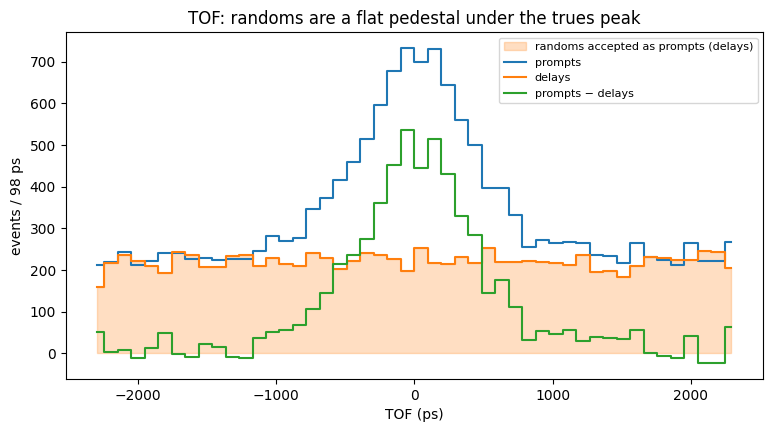

{"prompts_beyond_1000ps": 6496, "delays_beyond_1000ps": 5949, "prompts_over_delays_beyond_1000ps": 1.092, "tof_std_ps": {"prompts": 1147, "delays": 1344}, "uniform_window_std_ps": 1342}


In [7]:
print(plot_tof_randoms.call({}))

{"x_mm": -8.0, "y_mm": 8.0, "pixel_mm": 8.0}


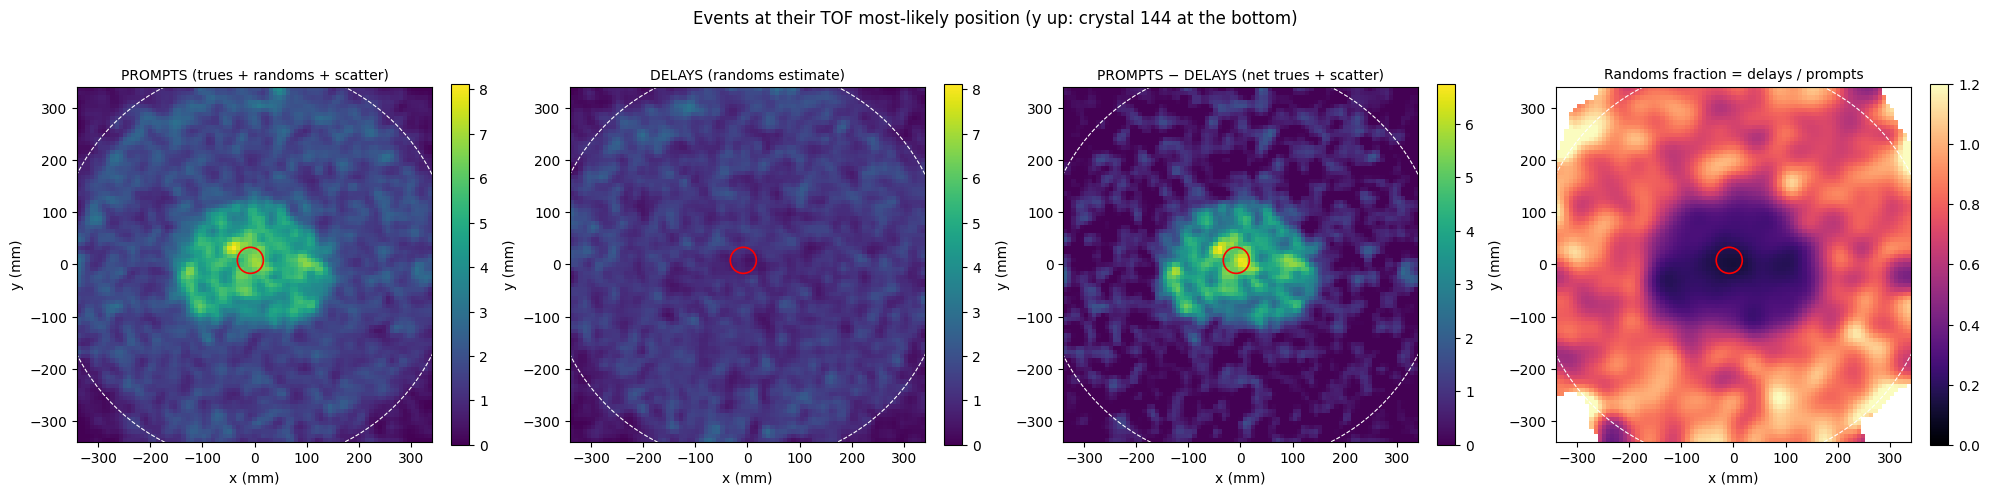

{"activity_center_mm": [-8.0, 8.0], "roi": {"roi_center_mm": [-8.0, 8.0], "roi_radius_mm": 25.0, "prompts": 201, "delays": 22, "net": 179, "randoms_fraction": 0.109, "delays_per_cm2_roi": 1.12, "delays_per_cm2_whole_fov": 2.054, "prompts_per_cm2_roi": 10.237}}


In [8]:
print(find_activity_center.call({}))
print(plot_tof_localized_images.call({"roi_radius_mm": 25}))

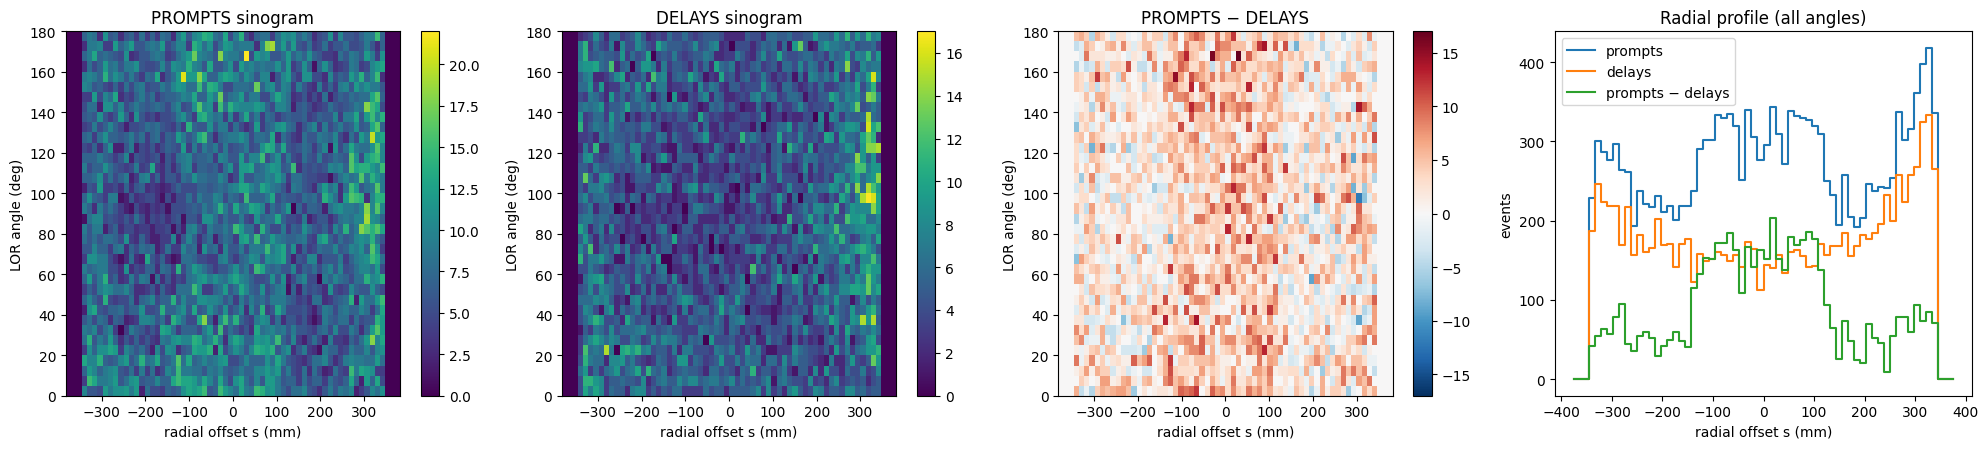

{"prompts_abs_s_gt_200mm": 6760, "delays_abs_s_gt_200mm": 5332, "prompts_over_delays_outside": 1.268, "note": "uniform random crystal pairs pile up near |s| = ring radius; that edge rise is geometric"}


In [9]:
print(plot_sinograms.call({}))

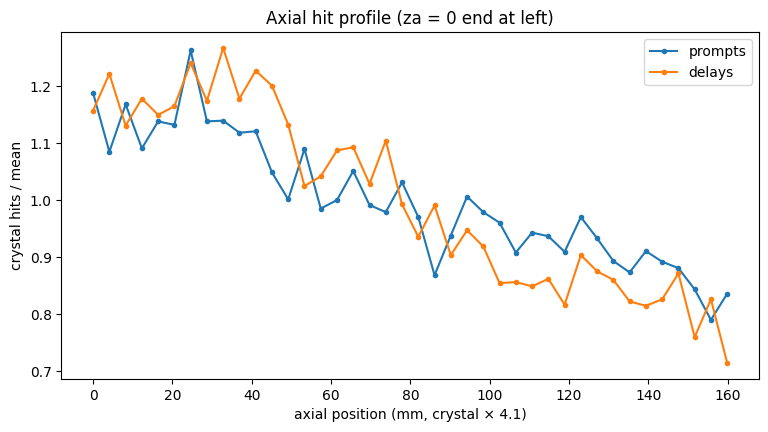

{"prompts": {"first5_over_last5": 1.336, "first5_rel_mean": 1.134, "last5_rel_mean": 0.849}, "delays": {"first5_over_last5": 1.46, "first5_rel_mean": 1.167, "last5_rel_mean": 0.8}}


In [12]:
print(plot_axial_profile.call({}))

In [13]:
# Compare the lung-insert ROI with an ROI of the same size in the hot body region, 70 mm from center
cx, cy = DATA["center"]
print("lung insert:", roi_randoms.call({"x_mm": cx, "y_mm": cy, "radius_mm": 25}))
print("body       :", roi_randoms.call({"x_mm": cx - 70, "y_mm": cy, "radius_mm": 25}))
print("outside    :", roi_randoms.call({"x_mm": cx + 250, "y_mm": cy, "radius_mm": 25}))

lung insert: {"roi_center_mm": [-8.0, 8.0], "roi_radius_mm": 25.0, "prompts": 201, "delays": 22, "net": 179, "randoms_fraction": 0.109, "delays_per_cm2_roi": 1.12, "delays_per_cm2_whole_fov": 2.054, "prompts_per_cm2_roi": 10.237}
body       : {"roi_center_mm": [-78.0, 8.0], "roi_radius_mm": 25.0, "prompts": 157, "delays": 32, "net": 125, "randoms_fraction": 0.204, "delays_per_cm2_roi": 1.63, "delays_per_cm2_whole_fov": 2.054, "prompts_per_cm2_roi": 7.996}
outside    : {"roi_center_mm": [242.0, 8.0], "roi_radius_mm": 25.0, "prompts": 58, "delays": 42, "net": 16, "randoms_fraction": 0.724, "delays_per_cm2_roi": 2.139, "delays_per_cm2_whole_fov": 2.054, "prompts_per_cm2_roi": 2.954}


## 6. Ask the agent

Claude gets the tools plus a system prompt describing the phantom setup, and chooses which tools to call.
`run_agent` returns the final message; the cells assign it to `_` so Colab does not print the raw object.


🤖 [turn 1] I'll load the file first, since all the other tools depend on it.
🔧 [turn 1] load_listprint({"path": "/content/iec_randoms50k.txt"})
🔧 [turn 2] plot_tof_randoms({})
🔧 [turn 2] plot_sinograms({})
🔧 [turn 2] find_activity_center({})


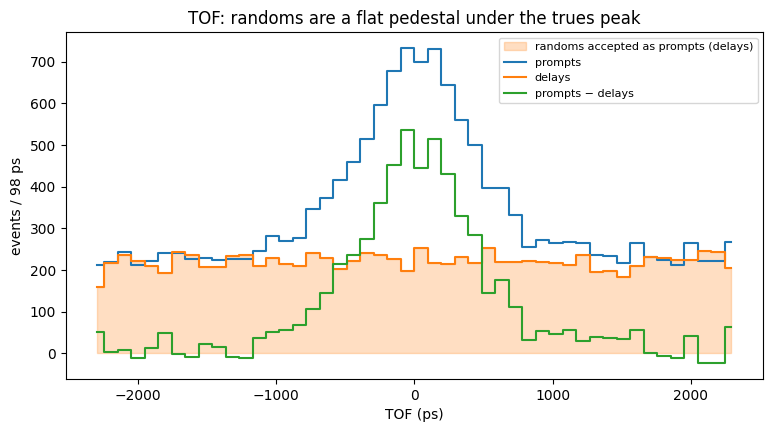

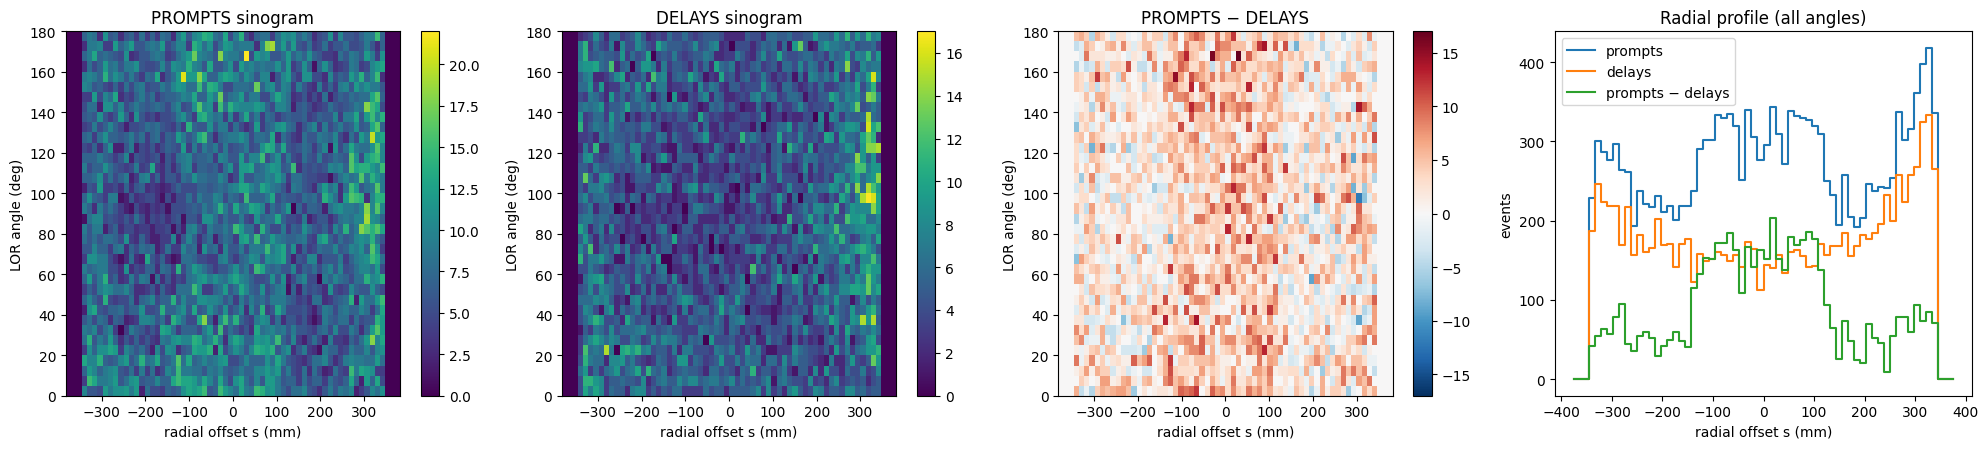

🔧 [turn 3] plot_tof_localized_images({"roi_radius_mm": 25})
🔧 [turn 3] roi_randoms({"x_mm": -8, "y_mm": 8, "radius_mm": 25})


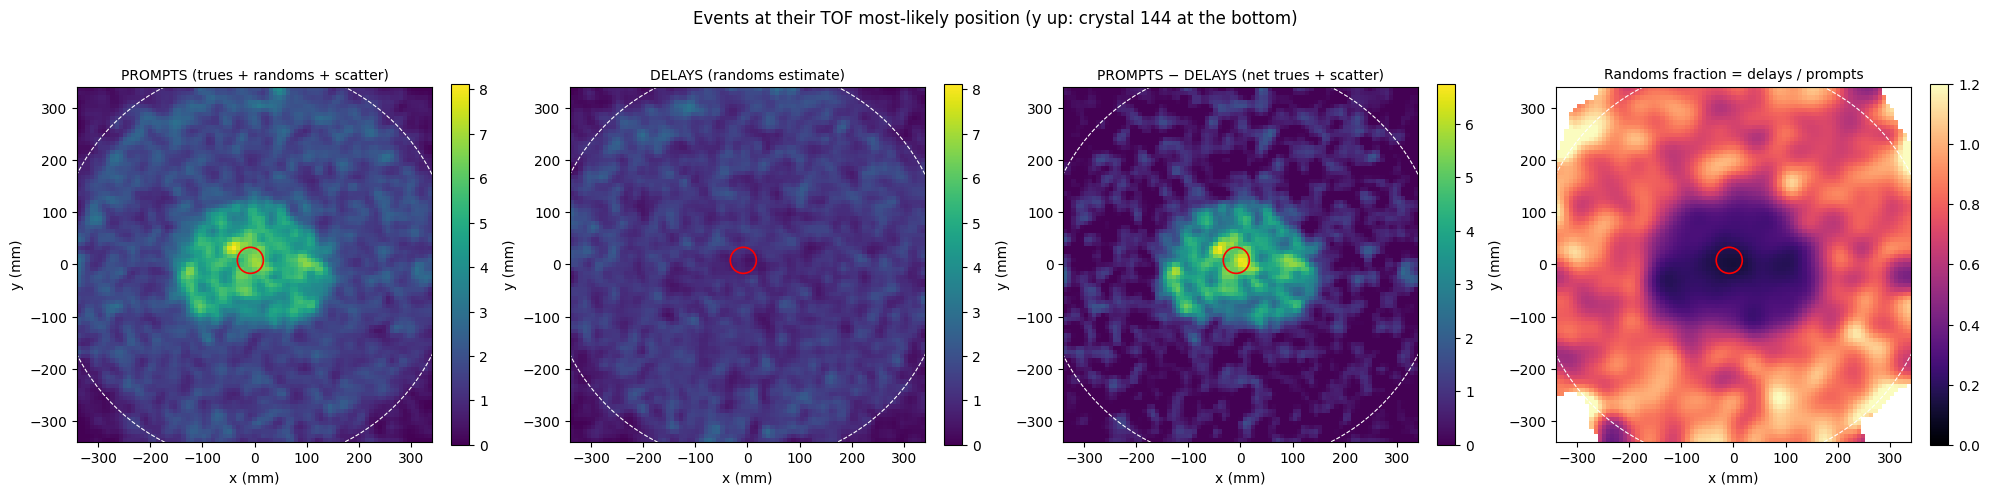


🤖 [turn 4] ## Randoms in IEC phantom data (3.19 s, 16,098 prompts)

### 1. What fraction of prompts are randoms?
- **Prompts:** 16,098 (5,053 cps). **Delays:** 10,579 (3,320 cps).
- **Randoms fraction = delays/prompts = 65.7% ± ~1%** (Poisson). Only about 5,519 counts (34%) are trues plus scatter.
- So **about 2 of every 3 accepted coincidences are randoms.** This is expected: the 968 µCi syringe and the 400 µCi foot source are outside the axial field of view. They produce many single events but few true coincidences. Randoms scale roughly as 2τ·S_a·S_b, so they grow with the square of the singles rate.

### 2. How good is the delays estimate?
- **TOF spectrum:** The delays' TOF spread (std 1,344 ps) matches a perfectly flat ±2.3 ns window (1,342 ps). So the delays form the expected flat background, while the prompts are narrower (1,147 ps) because they include a peak of trues.
- **Far TOF tails (|TOF| > 1,000 ps, more than 150 mm from the LOR midpoint):** prompts/delays = **1.09**. H

In [14]:
SYSTEM_PROMPT = """You are a PET physics assistant analyzing Philips Vereos list-mode data.

Scanner: 576 crystals around the ring (crystal 0 at 3 o'clock, clockwise), 40 axial crystals (4.1 mm pitch),
764 mm ring diameter, 320 ps timing resolution (~48 mm FWHM along an LOR), coincidence window +/-2.3 ns
for the 676 FOV (TOF bins -119..119 x 19.53 ps). PROMPT = trues + randoms + scatter; DELAY = randoms estimate.

Acquisition: NEMA/IEC body phantom with ~90 uCi in the background (body) compartment, no activity in the
spheres, a 5 cm diameter lung insert (no activity) at the phantom center, plus a 968 uCi syringe 1 cm in
front of the phantom and a 400 uCi source 1 cm beyond the foot end, both outside the axial FOV, to raise randoms.

Individual randoms cannot be identified; reason statistically by comparing prompts with delays.
The TOF-position images are not reconstructions: trues are blurred ~48 mm along each LOR there.
Use the tools to measure, report numbers with units, and explain the physics briefly."""


def run_agent(question: str, verbose: bool = True):
    """Run the agent on one question and return the final message."""
    runner = client.beta.messages.tool_runner(
        model=MODEL,
        max_tokens=16000,
        max_iterations=15,
        system=SYSTEM_PROMPT,
        tools=TOOLS,
        output_config={"effort": "high"},
        betas=["server-side-fallback-2026-07-01"],
        fallbacks="default",
        messages=[{"role": "user", "content": question}],
    )
    final = None
    for turn, message in enumerate(runner, start=1):
        final = message
        for block in message.content:
            if block.type == "text" and block.text.strip():
                print(f"\n🤖 [turn {turn}] {block.text}")
            elif block.type == "tool_use" and verbose:
                print(f"🔧 [turn {turn}] {block.name}({json.dumps(block.input)})")
    if final is not None and final.stop_reason == "refusal":
        print("⚠️ The request was declined:", final.stop_details)
    return final


_ = run_agent(
    f"Load {DATA_PATH}. What fraction of the accepted prompts are randoms, and how good is the delays "
    "estimate? Then estimate how much of the signal at the 5 cm lung insert at the phantom center is randoms, "
    "and explain why attenuation correction makes the randoms worse there."
)

🔧 [turn 1] load_listprint({"path": "/content/iec_randoms50k.txt"})
🔧 [turn 1] plot_axial_profile({})


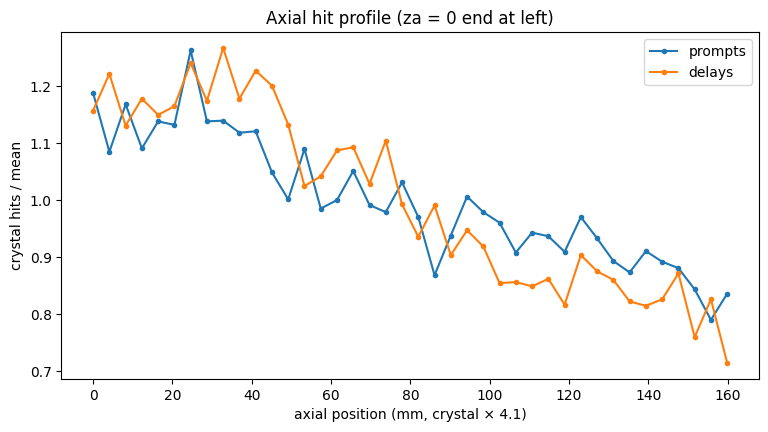


🤖 [turn 2] **Yes. Randoms rise toward the end with the low axial crystal numbers (rings 0–4). There, delays hit crystals about 46% more often than at the opposite end (rings 35–39).**

**What I measured** (16,098 prompts and 10,579 delays over 3.19 s; delays are 65.7% of prompts):

| Crystal hits (za + zb), relative to the mean over all 40 rings | First 5 rings | Last 5 rings | First ÷ last |
|---|---|---|---|
| Delays (randoms estimate) | 1.167 | 0.800 | **1.46** |
| Prompts | 1.134 | 0.849 | 1.34 |

**Is it real or just noise?**
- **Delays:** each delay hits two crystals, giving about 21,160 hits. That's roughly 3,090 hits in the first 5 rings and 2,120 in the last 5. Counting noise alone gives an uncertainty of about ±4%, so the ratio is **1.46 ± 0.04**. That is more than 10 standard deviations from 1, so the gradient is clearly real. The first end is about 17% above the mean and the last end about 20% below.
- **Prompts minus delays** (trues plus scatter), worked out from the same

In [15]:
_ = run_agent(
    f"Using {DATA_PATH}: is there evidence that the out-of-FOV sources raise randoms more at one axial end? "
    "Which end, and by how much?"
)

## 7. Notes and next steps

* **Statistics:** `iec_randoms50k.txt` is 50,000 data words (≈27k events, 3.2 s). ROI numbers carry Poisson
  noise of √N; a longer listPrint extract gives cleaner maps.
* **Randoms from singles:** with per-crystal singles rates S<sub>i</sub>, randoms per LOR = 2τ·S<sub>a</sub>·S<sub>b</sub>.
  This smooth estimate has less noise than the delays; a tool could compute crystal "singles-like" rates from the
  delays and build it.
* **Attenuation weighting:** to show the AC amplification directly, weight each event by the attenuation factor of
  its LOR through an ellipse model of the IEC body (µ = 0.096 /cm for water) and re-plot the delays image.
* **Compare scans:** load the low-randoms baseline scan (no out-of-FOV sources) and compare its lung-insert ROI with this one.